# DHVC 통계 시각화 — Re$_{\delta^*}$ 수렴·검증

MPM-STD `apps/dhvc` 출력(상수물성 OB, fig7)을 시각화한다. 참조 MPM-STD_C 와
출력 형식이 달라 새로 작성 — 우리는 **monitor.csv 가 아니라 로그**에 시계열을,
`dhvc_stats_<step>.dat` 에 **U(z) 프로파일**을 쓴다.

- **로그** `logs/dhvc_<Ra>_<jobid>.log` — 열: step · time · dt · max|div| · Re_dstar(누적) · u_max · sec/step
- **stats** `out_<Ra>/dhvc_stats_<step>.dat` — 헤더에 Re_dstar, 본문 `z  U_mean` (시간·xy 평균)
- **검증**: Re$_{\delta^*}$ = u_max·δ*/ν vs `PaScaL_TCS.csv` (Ra→Re_dstar)

실행하면 같은 폴더에 `dhvc_timeseries.png` · `dhvc_profiles.png` · `dhvc_validation.png`
로 저장하고 inline 으로도 띄운다.

In [1]:
import os, re, glob, csv
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")   # 노트북: 저장 + 화면
except NameError:
    matplotlib.use("Agg")                                   # 스크립트/배치
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

APP_DIR = "/shared/home/wel1come1234/workspace/MPM-STD/apps/dhvc"
if not os.path.isdir(os.path.join(APP_DIR, "plot")):
    APP_DIR = os.path.dirname(os.getcwd())   # plot/ 에서 실행 시 상위
PLOT_DIR = os.path.join(APP_DIR, "plot")
print("APP_DIR =", APP_DIR)

APP_DIR = /shared/home/wel1come1234/workspace/MPM-STD/apps/dhvc


In [2]:
# ── 파서 ──────────────────────────────────────────────────────────────────
def parse_log(path):
    """dhvc 로그 → {step,time,dt,div,re_dstar,u_max}. '# step' 헤더 뒤 7열 숫자행."""
    cols = {k: [] for k in ("step", "time", "dt", "div", "re_dstar", "u_max")}
    for line in open(path):
        parts = line.split()
        if len(parts) == 7 and not line.lstrip().startswith("#"):
            try:
                v = [float(x) for x in parts]
            except ValueError:
                continue
            cols["step"].append(v[0]); cols["time"].append(v[1]); cols["dt"].append(v[2])
            cols["div"].append(v[3]); cols["re_dstar"].append(v[4]); cols["u_max"].append(v[5])
    return {k: np.array(v) for k, v in cols.items()} if cols["step"] else None

def parse_stats(path):
    """dhvc_stats_*.dat → dict(step,time,re_dstar, z, U). 헤더 3줄(#)."""
    header = {}
    for line in open(path):
        if line.startswith("#"):
            for k, val in re.findall(r"(\w+)=([-\d.eE+]+)", line):
                header[k] = float(val)
            continue
            break
    data = np.loadtxt(path, comments="#")
    return dict(step=int(header.get("step", 0)), time=header.get("t", 0.0),
                re_dstar=header.get("Re_dstar", float("nan")),
                z=data[:, 0], U=data[:, 1])

def reynolds_delta_star(z, U, nu):
    """Re_δ* = u_max·δ*/ν (솔버 정의 1:1) — 프로파일에서 재계산(검산용)."""
    kmax = int(np.argmax(U)); u_max = U[kmax]
    if u_max <= 0: return 0.0, 0, 0.0
    zc = np.concatenate(([0.0], z[:kmax + 1]))
    f = np.concatenate(([1.0], 1.0 - U[:kmax + 1] / u_max))
    dstar = np.trapezoid(f, zc)
    return u_max * dstar / nu, kmax, dstar

# Ra 라벨 → 수치
def ra_value(label):
    return float(label.replace("e", "e"))

# 참조 Re_dstar (PaScaL_TCS.csv: Ra, Re_dstar)
ref = {}
pth = os.path.join(PLOT_DIR, "PaScaL_TCS.csv")
if os.path.exists(pth):
    for row in csv.reader(open(pth)):
        if len(row) == 2:
            ref[float(row[0])] = float(row[1])
def reference_re(ra, tol=0.3):
    for k, v in ref.items():
        if abs(k / ra - 1) < tol: return v
    return None
print("참조 Re_dstar:", {f"{k:.0e}": round(v, 3) for k, v in ref.items()})

참조 Re_dstar: {'1e+05': 5.378, '1e+06': 10.43, '1e+07': 22.947, '1e+08': 43.122, '1e+09': 62.963, '1e+10': 89.078}


In [3]:
# ── 케이스 자동 로드: logs/dhvc_<Ra>_<jobid>.log + out_<Ra>/dhvc_stats_*.dat ──
cases = {}
for log_path in sorted(glob.glob(os.path.join(APP_DIR, "logs", "dhvc_*_*.log"))):
    m = re.search(r"dhvc_(\w+?)_(\d+)\.log$", os.path.basename(log_path))
    if not m: continue
    label, job = m.group(1), m.group(2)
    log = parse_log(log_path)
    if log is None: continue
    sfiles = sorted(glob.glob(os.path.join(APP_DIR, f"out_{label}", "dhvc_stats_*.dat")),
                    key=lambda p: int(re.search(r"(\d+)", os.path.basename(p)).group(1)))
    stats = [parse_stats(p) for p in sfiles]
    ra = ra_value(label)
    nu = (0.7 / ra) ** 0.5
    cases[label] = dict(label=label, job=job, log=log, stats=stats, ra=ra, nu=nu)
    last_re = log["re_dstar"][-1] if len(log["re_dstar"]) else float("nan")
    tgt = reference_re(ra)
    tgt_s = f"{tgt:.3f} ({100*(last_re/tgt-1):+.1f}%)" if tgt else "—"
    print(f"Ra={label:>4} job {job}: 로그 {len(log['step'])}행 t={log['time'][-1]:.1f} "
          f"Re_dstar(누적)={last_re:.3f}  vs PaScaL {tgt_s}  / stats {len(stats)}개")
assert cases, "로드된 DHVC 케이스가 없다 — 런이 아직 통계를 안 썼을 수 있음"
colors = {lab: plt.cm.viridis(v) for lab, v in zip(cases, np.linspace(0.0, 0.8, len(cases)))}

Ra= 1e5 job 35578: 로그 548행 t=180.2 Re_dstar(누적)=4.875  vs PaScaL 5.378 (-9.3%)  / stats 4개
Ra= 1e6 job 35579: 로그 555행 t=130.0 Re_dstar(누적)=9.552  vs PaScaL 10.430 (-8.4%)  / stats 2개


## 1. 시계열 — Re$_{\delta^*}$ 수렴·안정성

Font 'default' does not have a glyph for '\ub204' [U+b204], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\uc801' [U+c801], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\ub204' [U+b204], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\uc801' [U+c801], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\ub204' [U+b204], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\uc801' [U+c801], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\ub204' [U+b204], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\uc801' [U+c801], substituting with a dummy symbol.


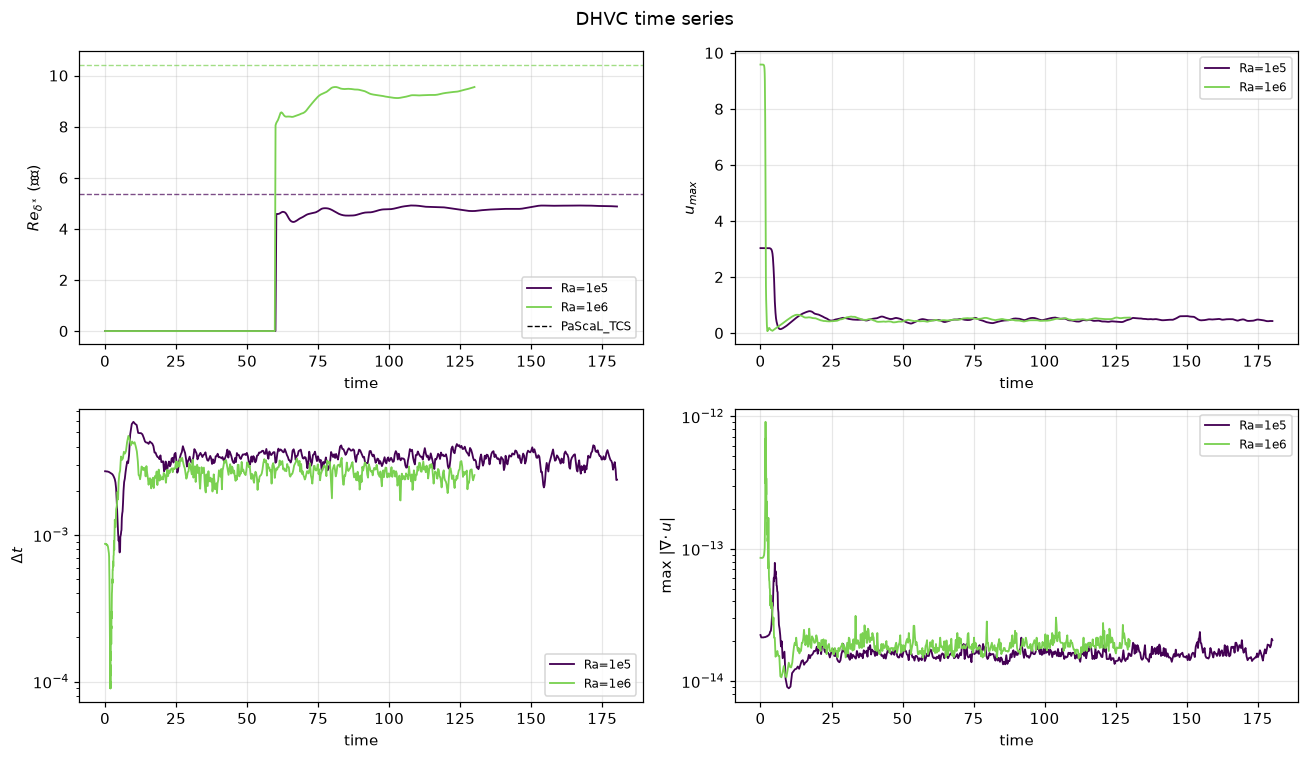

In [4]:
panels = [("re_dstar", r"$Re_{\delta^*}$ (누적)", False),
          ("u_max", r"$u_{max}$", False),
          ("dt", r"$\Delta t$", True),
          ("div", r"max $|\nabla\!\cdot u|$", True)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7)); axes = axes.ravel()
for ax, (key, ylab, ylog) in zip(axes, panels):
    for lab, c in cases.items():
        ax.plot(c["log"]["time"], c["log"][key], color=colors[lab], lw=1.2,
                label=f"Ra={lab}")
    if key == "re_dstar":
        for lab, c in cases.items():
            tgt = reference_re(c["ra"])
            if tgt: ax.axhline(tgt, color=colors[lab], ls="--", lw=0.9, alpha=0.7)
        ax.plot([], [], "k--", lw=0.9, label="PaScaL_TCS")
    if ylog: ax.set_yscale("log")
    ax.set_xlabel("time"); ax.set_ylabel(ylab); ax.legend(fontsize=8)
fig.suptitle("DHVC time series"); fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "dhvc_timeseries.png"), dpi=150); plt.show()

## 2. 평균 유속 프로파일 $U(z)$ 와 $\delta^*$

[1e5] 프로파일 Re_dstar=4.876 (u_max=0.4718 @ z=0.0981, δ*=0.0273)  헤더값=4.876
[1e6] 프로파일 Re_dstar=9.321 (u_max=0.4787 @ z=0.0678, δ*=0.0163)  헤더값=9.321


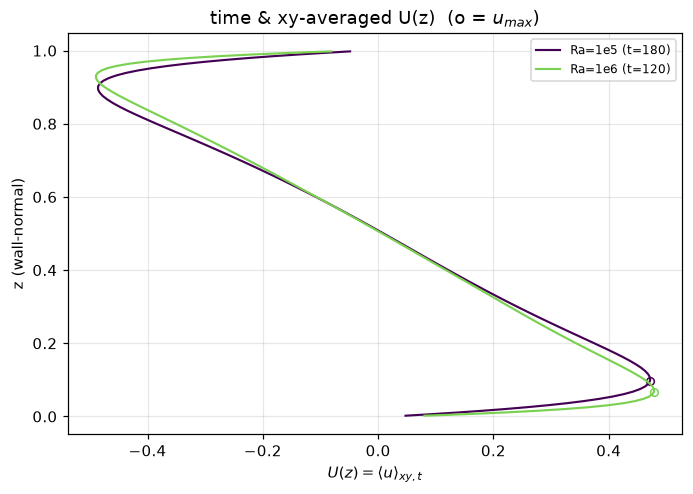

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for lab, c in cases.items():
    if not c["stats"]:
        print(f"[{lab}] stats 아직 없음 — 프로파일 생략"); continue
    s = c["stats"][-1]                      # 최신(가장 수렴된) 프로파일
    ax.plot(s["U"], s["z"], color=colors[lab], lw=1.4, label=f"Ra={lab} (t={s['time']:.0f})")
    re_chk, kmax, dstar = reynolds_delta_star(s["z"], s["U"], c["nu"])
    ax.plot(s["U"][kmax], s["z"][kmax], "o", color=colors[lab], ms=5, mfc="none")
    print(f"[{lab}] 프로파일 Re_dstar={re_chk:.3f} (u_max={s['U'][kmax]:.4f} @ z={s['z'][kmax]:.4f}, "
          f"δ*={dstar:.4f})  헤더값={s['re_dstar']:.3f}")
ax.set_xlabel(r"$U(z)=\langle u\rangle_{xy,t}$"); ax.set_ylabel("z (wall-normal)")
ax.set_title(r"time & xy-averaged U(z)  (o = $u_{max}$)")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "dhvc_profiles.png"), dpi=150); plt.show()

## 3. 검증 — Re$_{\delta^*}$(Ra) vs 참조

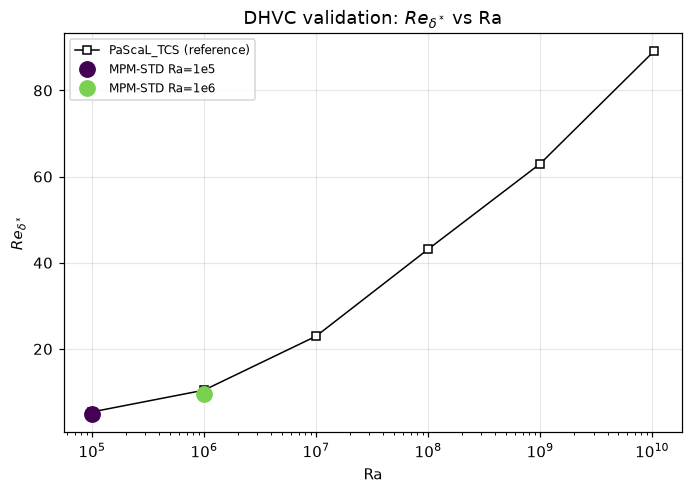


요약:
  Ra= 1e5: Re_dstar=4.875  참조 5.377663301342727  편차 -9.3%  (t=180)
  Ra= 1e6: Re_dstar=9.552  참조 10.429532461863907  편차 -8.4%  (t=130)


In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ras = np.array(sorted(ref)); res = np.array([ref[r] for r in ras])
ax.plot(ras, res, "ks-", ms=5, mfc="white", lw=1, label="PaScaL_TCS (reference)")
for lab, c in cases.items():
    re_last = c["log"]["re_dstar"][-1]
    ax.plot(c["ra"], re_last, "o", color=colors[lab], ms=10, label=f"MPM-STD Ra={lab}")
ax.set_xscale("log"); ax.set_xlabel("Ra"); ax.set_ylabel(r"$Re_{\delta^*}$")
ax.set_title("DHVC validation: " + r"$Re_{\delta^*}$ vs Ra")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "dhvc_validation.png"), dpi=150); plt.show()
print("\n요약:")
for lab, c in cases.items():
    tgt = reference_re(c["ra"]); re_last = c["log"]["re_dstar"][-1]
    dev = f"{100*(re_last/tgt-1):+.1f}%" if tgt else "—"
    print(f"  Ra={lab:>4}: Re_dstar={re_last:.3f}  참조 {tgt}  편차 {dev}  "
          f"(t={c['log']['time'][-1]:.0f})")